<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/05_sleep_health_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.png" alt="Open in Colab"/></a>

# Sleep Health and Lifestyle Classification with a Support Vector Machine

## Research question

Can sleep, lifestyle, and basic health measurements classify an observation into `None`, `Insomnia`, or `Sleep Apnea` using an RBF-kernel Support Vector Machine (SVM)?

**Purpose of the analysis.** This is a supervised multiclass-classification exercise. The target is a category, not a continuous number. The notebook demonstrates how SVM uses a margin and a kernel to separate classes after numeric and categorical features have been prepared safely.

> **Health caution:** The labels are dataset categories, not a medical diagnosis. This notebook is for machine-learning education and should not be used to diagnose a person.

## 1. Basic definitions and formulas

| Term | Simple meaning |
| --- | --- |
| Classification | Predict a category, here `None`, `Insomnia`, or `Sleep Apnea`. |
| Multiclass classification | Predict one class from more than two possible classes. |
| SVM | Finds a decision boundary that separates classes while trying to keep a wide safety margin. |
| Margin | The distance between the boundary and the closest training observations. |
| Support vectors | The observations closest to the boundary; they help determine the boundary. |
| Kernel | A function that lets SVM represent nonlinear relationships without manually drawing new features. |
| RBF kernel | A similarity function that gives high similarity to nearby points and lower similarity to distant points. |
| Standardization | Transform features so they have comparable scale before SVM calculates distances/similarities. |

### Linear SVM idea

For a simple binary problem, the decision boundary can be written as:

$$w^Tx+b=0$$

- $x$ = input feature vector
- $w$ = learned weights
- $b$ = intercept

The SVM tries to separate the classes while maximizing the margin. Observations closest to the boundary become the support vectors.

### RBF kernel

$$K(x,x')=\exp(-\gamma\lVert x-x'\rVert^2)$$

- $x,x'$ = two observations
- $\lVert x-x'\rVert^2$ = squared distance between them
- $\gamma$ = how quickly similarity falls as observations become farther apart

The RBF kernel is useful when the class boundary is curved rather than a straight line.

### Important SVM parameters

- **$C$:** controls the penalty for classification errors. A larger $C$ tries harder to classify training rows correctly and can overfit; a smaller $C$ allows more errors for a wider, smoother margin.
- **$\gamma$:** controls how local each RBF influence is. A large $\gamma$ creates very local, complex boundaries; a small $\gamma$ creates smoother, broader boundaries.

This notebook uses a fixed baseline of `C=1.0` and `gamma="scale"`. Cross-validation and parameter tuning would be appropriate before making stronger claims.

## 2. Dataset, source, and problem statement

**Source.** [Sleep Health and Lifestyle Dataset](https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset), published by `uom190346a` on Kaggle. The expected file is `Sleep_health_and_lifestyle_dataset.csv`. Download the exact version, record the access date, and place it beside this notebook, in `data/`, or in `/content/`.

The dataset includes age, gender, occupation, sleep duration, quality of sleep, physical activity, stress, BMI category, blood pressure, heart rate, daily steps, and a sleep-disorder label.

**Target definition.** Missing `Sleep Disorder` values are mapped to `None` because the source convention uses a blank value for no recorded disorder. This is a modeling assumption, not a clinical conclusion.

**Problem statement.** Use lifestyle and health measurements to classify the recorded sleep-disorder category. The model can demonstrate patterns in this sample, but it cannot diagnose insomnia or sleep apnea.

**INSIGHT - 1:** This is multiclass classification because there are three possible target categories. Accuracy alone can hide weak performance on a smaller class, so per-class precision, recall, F1, confusion matrices, macro averages, and ROC-AUC are reported.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    balanced_accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

In [2]:
DATA_FILENAME = "Sleep_health_and_lifestyle_dataset.csv"
candidates = [
    Path(DATA_FILENAME),
    Path("data") / DATA_FILENAME,
    Path("/content") / DATA_FILENAME,
    Path("/content/drive/MyDrive") / DATA_FILENAME,
]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Download Sleep_health_and_lifestyle_dataset.csv from the cited Kaggle source and place it beside this notebook, in data/, or in /content/.")

df_raw = pd.read_csv(dataset_path)
required = {"Sleep Disorder", "Blood Pressure", "Age", "Sleep Duration", "Quality of Sleep", "Stress Level", "BMI Category"}
missing = required - set(df_raw.columns)
if missing:
    raise KeyError(f"Missing required columns: {sorted(missing)}")
df_raw["Sleep Disorder"] = df_raw["Sleep Disorder"].fillna("None").replace("", "None")
print(f"Loaded {dataset_path}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded data/Sleep_health_and_lifestyle_dataset.csv: 374 rows x 13 columns


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


,dtype
Person ID,int64
Gender,str
Age,int64
Occupation,str
Sleep Duration,float64
Quality of Sleep,int64
Physical Activity Level,int64
Stress Level,int64
BMI Category,str
Blood Pressure,str


,missing_values
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


,count,percentage
Sleep Disorder,,
None,219,58.556150
Sleep Apnea,78,20.855615
Insomnia,77,20.588235


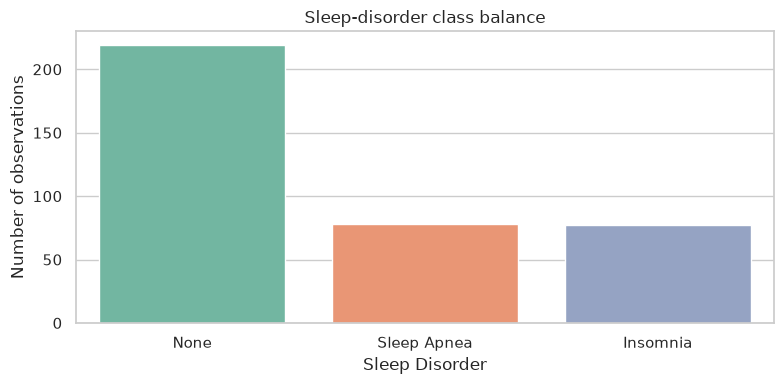

In [3]:
display(df_raw.dtypes.rename("dtype").to_frame())
display(df_raw.isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())
target_summary = df_raw["Sleep Disorder"].value_counts().to_frame("count")
target_summary["percentage"] = target_summary["count"] / len(df_raw) * 100
display(target_summary)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=target_summary.reset_index(), x="Sleep Disorder", y="count", hue="Sleep Disorder", palette="Set2", legend=False, ax=ax)
ax.set_title("Sleep-disorder class balance")
ax.set_ylabel("Number of observations")
plt.tight_layout()
plt.show()

## 3. Data cleaning and preprocessing

The cleaning steps are:

1. Replace missing `Sleep Disorder` labels with `None`, following the source convention.
2. Remove exact duplicates and unusable target rows.
3. Split the composite `Blood Pressure` string into numeric systolic and diastolic measurements.
4. Remove `Person ID`, which is an identifier rather than a health characteristic.
5. Keep useful numeric and categorical predictors.
6. Fit imputation, one-hot encoding, and scaling inside a pipeline using training data only.

The original `Blood Pressure` text column is not used after splitting because SVM needs numeric inputs. The categorical variables are encoded into indicator columns so the model can use them.

In [4]:
df = df_raw.drop_duplicates().copy()
before_rows = len(df_raw)
df = df.dropna(subset=["Sleep Disorder"]).copy()

bp_parts = df["Blood Pressure"].astype(str).str.split("/", expand=True)
df["Systolic_BP"] = pd.to_numeric(bp_parts[0], errors="coerce")
df["Diastolic_BP"] = pd.to_numeric(bp_parts[1], errors="coerce")
df = df.drop(columns=["Person ID", "Blood Pressure"], errors="ignore")

print(f"Exact duplicate rows removed: {before_rows - len(df_raw.drop_duplicates()):,}")
print(f"Rows with missing target removed: {len(df_raw) - len(df):,}")
print(f"Rows with invalid blood-pressure parsing: {df[['Systolic_BP', 'Diastolic_BP']].isna().any(axis=1).sum():,}")
print(f"Clean analysis table: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
display(df.isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())

Exact duplicate rows removed: 0
Rows with missing target removed: 0
Rows with invalid blood-pressure parsing: 0
Clean analysis table: 374 rows x 13 columns


,missing_values
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Heart Rate,0
Daily Steps,0


In [5]:
numeric_features = [
    "Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
    "Stress Level", "Heart Rate", "Daily Steps", "Systolic_BP", "Diastolic_BP",
]
categorical_features = ["Gender", "Occupation", "BMI Category"]
display(df[numeric_features].describe().T)
print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

,count,mean,std,min,25%,50%,75%,max
Age,374.0,42.184492,8.673133,27.0,35.25,43.0,50.0,59.0
Sleep Duration,374.0,7.132086,0.795657,5.8,6.40,7.2,7.8,8.5
Quality of Sleep,374.0,7.312834,1.196956,4.0,6.00,7.0,8.0,9.0
Physical Activity Level,374.0,59.171123,20.830804,30.0,45.00,60.0,75.0,90.0
Stress Level,374.0,5.385027,1.774526,3.0,4.00,5.0,7.0,8.0
Heart Rate,374.0,70.165775,4.135676,65.0,68.00,70.0,72.0,86.0
Daily Steps,374.0,6816.844920,1617.915679,3000.0,5600.00,7000.0,8000.0,10000.0
Systolic_BP,374.0,128.553476,7.748118,115.0,125.00,130.0,135.0,142.0
Diastolic_BP,374.0,84.649733,6.161611,75.0,80.00,85.0,90.0,95.0


Numeric features: ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic_BP', 'Diastolic_BP']
Categorical features: ['Gender', 'Occupation', 'BMI Category']


**INSIGHT - 2:** `Person ID` is removed because it identifies a row but does not describe sleep health. Keeping an identifier can let a model memorize accidental row patterns without learning a relationship that generalizes.

**INSIGHT - 3:** Splitting blood pressure preserves useful information from a combined text field. For example, systolic and diastolic pressure may have different relationships with the target, so keeping them as two numbers is more informative than treating `126/83` as one category.

**INSIGHT - 4:** The pipeline will learn numeric medians, categorical modes, category vocabulary, and scaling parameters from training data only. This prevents the test set from quietly influencing the model.

## 4. Exploratory data analysis

EDA is used to understand the sample before fitting SVM. We inspect numerical distributions, sleep-disorder rates across important categories, and relationships among numeric measurements. These are descriptive patterns, not medical causation.

In [6]:
summary = df[numeric_features].describe().T
summary["median"] = df[numeric_features].median()
summary["iqr"] = summary["75%"] - summary["25%"]
display(summary[["mean", "median", "std", "min", "25%", "50%", "75%", "max", "iqr"]])

,mean,median,std,min,25%,50%,75%,max,iqr
Age,42.184492,43.0,8.673133,27.0,35.25,43.0,50.0,59.0,14.75
Sleep Duration,7.132086,7.2,0.795657,5.8,6.40,7.2,7.8,8.5,1.40
Quality of Sleep,7.312834,7.0,1.196956,4.0,6.00,7.0,8.0,9.0,2.00
Physical Activity Level,59.171123,60.0,20.830804,30.0,45.00,60.0,75.0,90.0,30.00
Stress Level,5.385027,5.0,1.774526,3.0,4.00,5.0,7.0,8.0,3.00
Heart Rate,70.165775,70.0,4.135676,65.0,68.00,70.0,72.0,86.0,4.00
Daily Steps,6816.844920,7000.0,1617.915679,3000.0,5600.00,7000.0,8000.0,10000.0,2400.00
Systolic_BP,128.553476,130.0,7.748118,115.0,125.00,130.0,135.0,142.0,10.00
Diastolic_BP,84.649733,85.0,6.161611,75.0,80.00,85.0,90.0,95.0,10.00


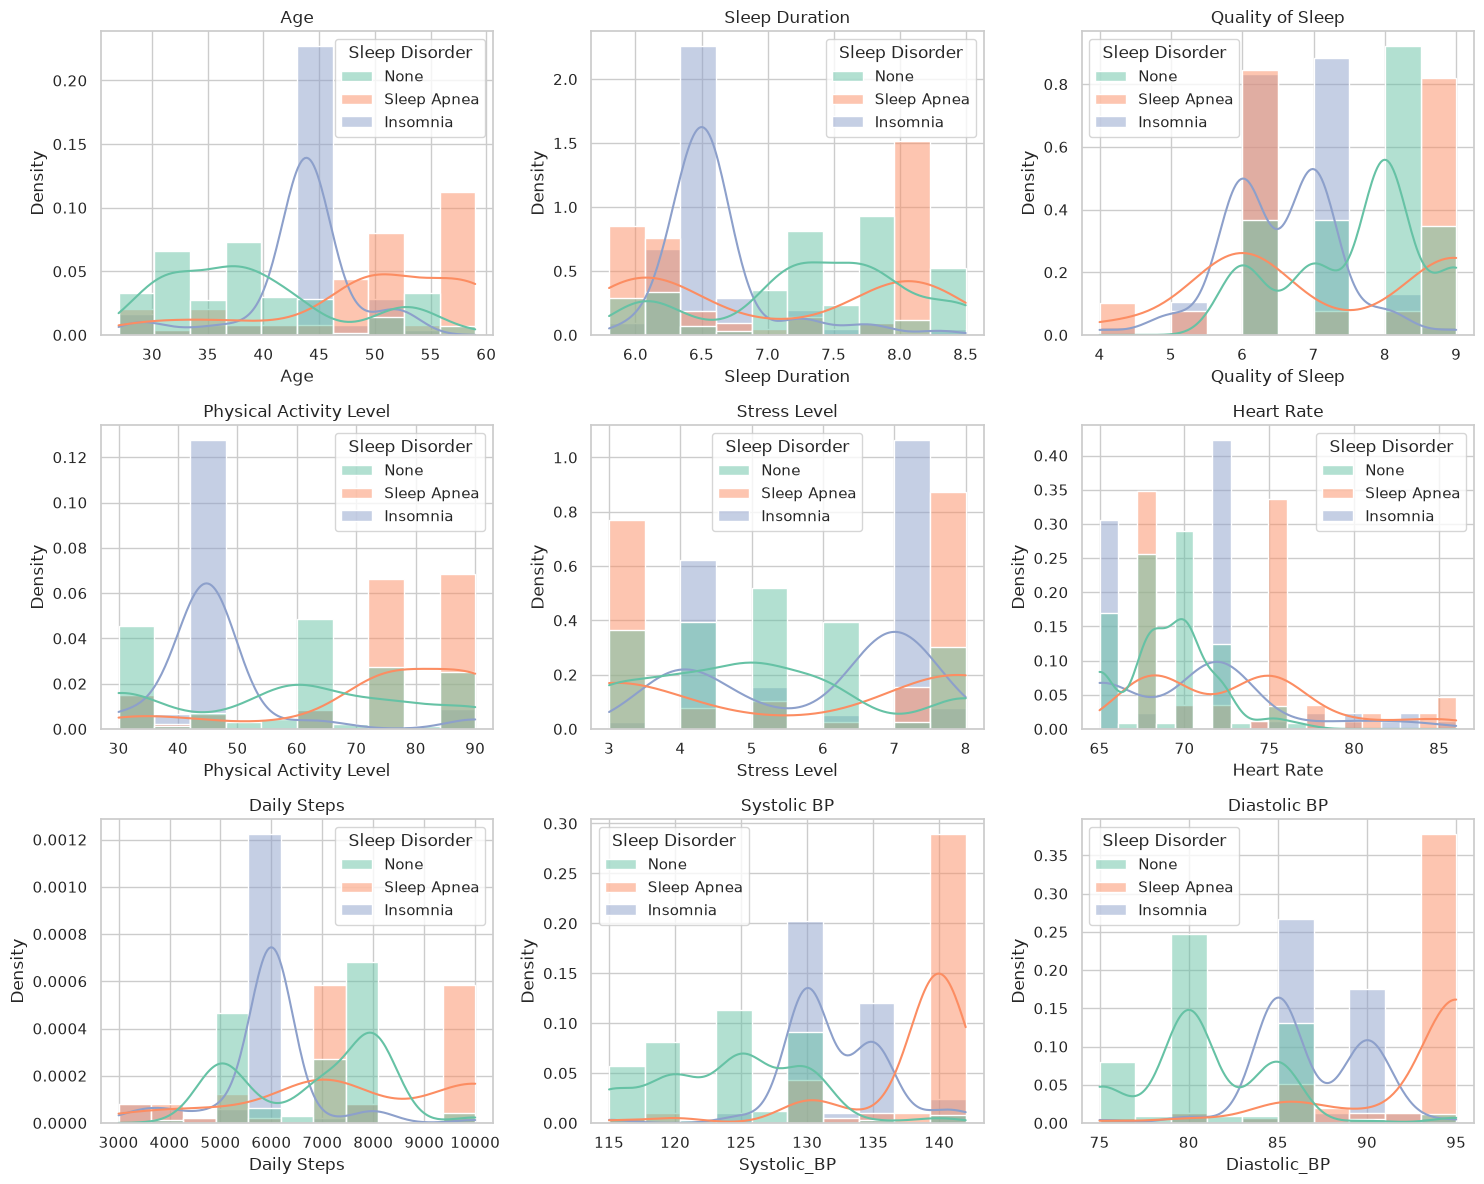

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, column in zip(axes.ravel(), numeric_features):
    sns.histplot(data=df, x=column, hue="Sleep Disorder", kde=True, stat="density", common_norm=False, palette="Set2", ax=ax)
    ax.set_title(column.replace("_", " "))
plt.tight_layout()
plt.show()

,disorder_percentage_by_BMI_Category
BMI Category,
Obese,100.000000
Overweight,87.162162
Normal Weight,19.047619
Normal,6.153846


,disorder_percentage_by_Occupation
Occupation,
Sales Representative,100.000000
Salesperson,93.750000
Nurse,87.671233
Teacher,77.500000
Scientist,50.000000
Software Engineer,25.000000
Accountant,18.918919
Lawyer,10.638298
Doctor,9.859155


,disorder_percentage_by_Gender
Gender,
Female,55.675676
Male,27.513228


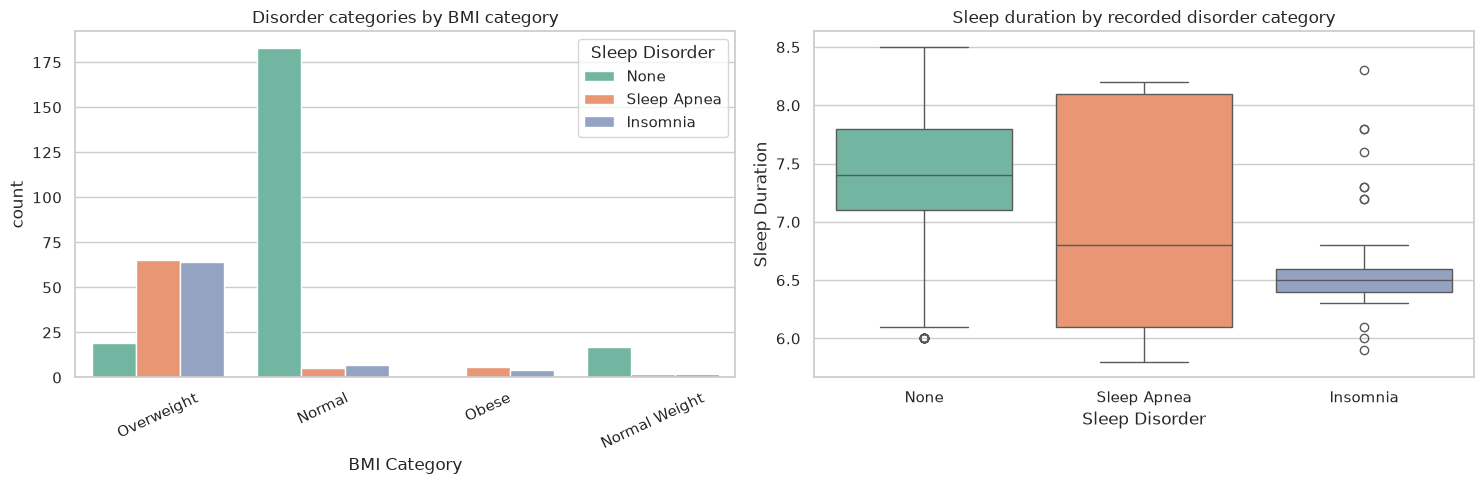

In [8]:
for column in ["BMI Category", "Occupation", "Gender"]:
    rates = df.groupby(column)["Sleep Disorder"].apply(lambda values: (values != "None").mean() * 100).sort_values(ascending=False)
    display(rates.rename(f"disorder_percentage_by_{column.replace(' ', '_')}").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="BMI Category", hue="Sleep Disorder", palette="Set2", ax=axes[0])
axes[0].set_title("Disorder categories by BMI category")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=df, x="Sleep Disorder", y="Sleep Duration", hue="Sleep Disorder", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Sleep duration by recorded disorder category")
plt.tight_layout()
plt.show()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic_BP,Diastolic_BP
Age,1.000000,0.344709,0.473734,0.178993,-0.422344,-0.225606,0.057973,0.605878,0.593839
Sleep Duration,0.344709,1.000000,0.883213,0.212360,-0.811023,-0.516455,-0.039533,-0.180406,-0.166570
Quality of Sleep,0.473734,0.883213,1.000000,0.192896,-0.898752,-0.659865,0.016791,-0.121632,-0.110151
Physical Activity Level,0.178993,0.212360,0.192896,1.000000,-0.034134,0.136971,0.772723,0.265416,0.382651
Stress Level,-0.422344,-0.811023,-0.898752,-0.034134,1.000000,0.670026,0.186829,0.102818,0.091811
Heart Rate,-0.225606,-0.516455,-0.659865,0.136971,0.670026,1.000000,-0.030309,0.294143,0.271092
Daily Steps,0.057973,-0.039533,0.016791,0.772723,0.186829,-0.030309,1.000000,0.103342,0.241986
Systolic_BP,0.605878,-0.180406,-0.121632,0.265416,0.102818,0.294143,0.103342,1.000000,0.972885
Diastolic_BP,0.593839,-0.166570,-0.110151,0.382651,0.091811,0.271092,0.241986,0.972885,1.000000


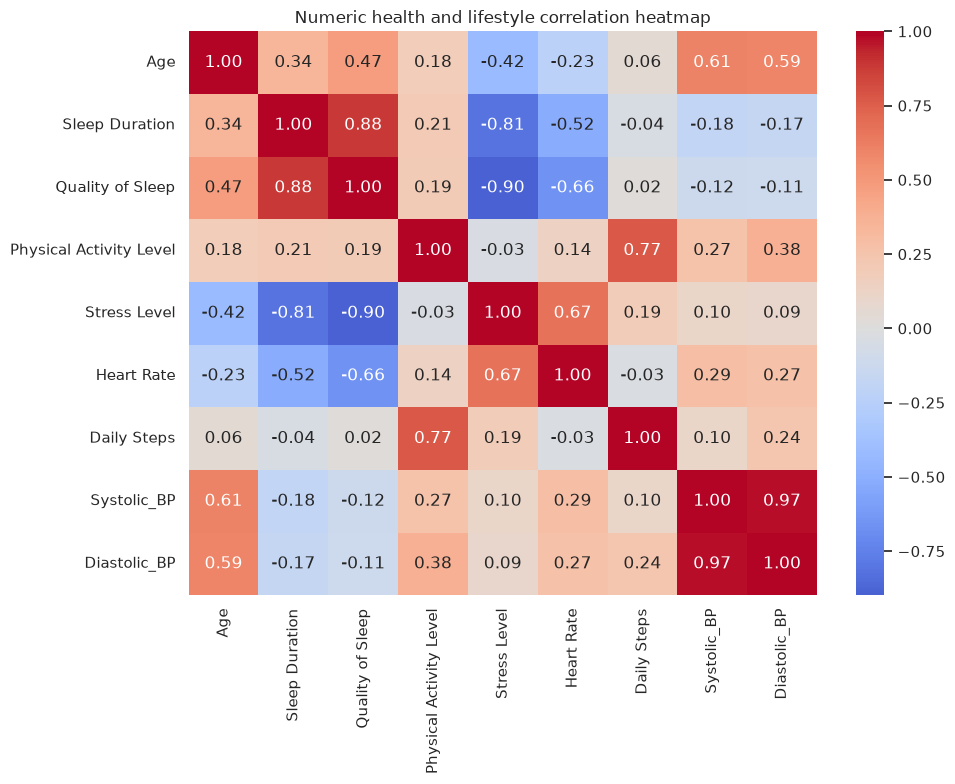

In [9]:
numeric_correlation = df[numeric_features].corr()
display(numeric_correlation)
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_correlation, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Numeric health and lifestyle correlation heatmap")
plt.tight_layout()
plt.show()

**INSIGHT - 5:** The mean, median, standard deviation, and IQR describe the center and spread of the health and lifestyle measurements. Large differences in scale reinforce why StandardScaler must be fitted before an RBF SVM.

**INSIGHT - 6:** Group plots can show associations, such as different recorded-disorder rates across BMI categories or sleep-duration patterns. They do not prove that BMI or sleep duration causes a disorder, and the sample may contain demographic or collection bias.

**INSIGHT - 7:** Overlapping class distributions are expected in health data. If the classes were perfectly separated by one variable, a complex nonlinear classifier would be unnecessary. SVM is useful here because it can combine several partially informative features.

**INSIGHT - 8:** Correlation only measures pairwise linear association among numeric variables. The RBF kernel can represent nonlinear boundaries and interactions that are not visible in this heatmap.

## 5. Feature selection and processing

The model retains numeric health/lifestyle measurements plus `Gender`, `Occupation`, and `BMI Category`. These features are kept because they describe the person or the reported sleep context. The target `Sleep Disorder` is never included in `X`.

`Person ID` is excluded as an identifier. The composite blood-pressure string is replaced by numeric systolic and diastolic values. The model uses an 80/20 stratified split:

- **80% training:** fit preprocessing, learn the SVM boundary, and perform cross-validation.
- **20% testing:** remain untouched until the final evaluation.

The split is stratified so each partition preserves approximately the same proportions of `None`, `Insomnia`, and `Sleep Apnea`. This is important because the classes are not equally represented. The 80/20 ratio is a common baseline, not a universal rule; repeated or nested cross-validation could provide stronger uncertainty estimates for a small dataset.

In [10]:
X = df[numeric_features + categorical_features].copy()
y = df["Sleep Disorder"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Training rows: {len(X_train):,} ({len(X_train) / len(X):.0%})")
print(f"Testing rows: {len(X_test):,} ({len(X_test) / len(X):.0%})")
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

Training rows: 299 (80%)
Testing rows: 75 (20%)
Training class proportions:


,proportion
Sleep Disorder,
None,0.585284
Sleep Apnea,0.207358
Insomnia,0.207358


In [11]:
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder),
    ]), categorical_features),
])

svm_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42)),
])
print("Pipeline created: imputation -> one-hot encoding -> scaling -> balanced RBF SVM")

Pipeline created: imputation -> one-hot encoding -> scaling -> balanced RBF SVM


**INSIGHT - 9:** SVM is sensitive to feature scale because its boundary and RBF similarity depend on distances. Scaling is therefore not cosmetic; it changes how the model measures similarity between observations.

**INSIGHT - 10:** `class_weight="balanced"` gives more influence to classes with fewer training observations. This can improve minority-class recall, but it may also increase false positives. The confusion matrix and per-class metrics show whether that trade-off is useful.

## 6. Model implementation and evaluation

The baseline uses an RBF-kernel SVM with `C=1.0` and `gamma="scale"`. A stratified five-fold cross-validation provides a stability check on the training partition before the final test evaluation.

Because this is multiclass classification, the notebook reports:

- accuracy;
- per-class precision, recall, and F1;
- macro averages, which give every class equal importance;
- weighted averages, which reflect class frequency;
- balanced accuracy;
- one-vs-rest ROC-AUC using predicted probabilities.

The classification report is more informative than accuracy alone because a strong result on the majority `None` category can hide weak recognition of `Insomnia` or `Sleep Apnea`.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_result = cross_validate(svm_model, X_train, y_train, cv=cv, scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "f1_macro": "f1_macro"}, n_jobs=-1)
cv_summary = pd.DataFrame({
    "mean": [cv_result["test_accuracy"].mean(), cv_result["test_balanced_accuracy"].mean(), cv_result["test_f1_macro"].mean()],
    "std": [cv_result["test_accuracy"].std(), cv_result["test_balanced_accuracy"].std(), cv_result["test_f1_macro"].std()],
}, index=["accuracy", "balanced_accuracy", "macro_f1"])
display(cv_summary)

,mean,std
accuracy,0.886102,0.031542
balanced_accuracy,0.861990,0.042063
macro_f1,0.859848,0.036695


In [13]:
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)
y_scores = svm_model.decision_function(X_test)
train_pred = svm_model.predict(X_train)
classes = svm_model.named_steps["classifier"].classes_
support_counts = svm_model.named_steps["classifier"].n_support_
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Support-vector counts by class: {dict(zip(classes, support_counts))}")
print(f"Train accuracy: {train_accuracy:.2%}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Generalization gap: {abs(train_accuracy - test_accuracy):.2%}")

Support-vector counts by class: {'Insomnia': np.int32(22), 'None': np.int32(73), 'Sleep Apnea': np.int32(24)}
Train accuracy: 90.64%
Test accuracy: 96.00%
Generalization gap: 5.36%


In [14]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Macro precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro recall / sensitivity": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro F1 score": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Weighted F1 score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "Multiclass ROC-AUC": np.mean([roc_auc_score((y_test == class_name).astype(int), y_scores[:, index]) for index, class_name in enumerate(classes)]),
}, name="test_value")
display(test_metrics.to_frame())
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, zero_division=0))

,test_value
Accuracy,0.960000
Balanced accuracy,0.947980
Macro precision,0.947368
Macro recall / sensitivity,0.947980
Macro F1 score,0.943788
Weighted F1 score,0.960685
Multiclass ROC-AUC,0.991757


              precision    recall  f1-score   support

    Insomnia       1.00      0.87      0.93        15
        None       1.00      0.98      0.99        44
 Sleep Apnea       0.84      1.00      0.91        16

    accuracy                           0.96        75
   macro avg       0.95      0.95      0.94        75
weighted avg       0.97      0.96      0.96        75



**INSIGHT - 11:** The cross-validation mean shows typical training-fold performance, while the standard deviation shows how much that performance changes across folds. A high standard deviation means the result is sensitive to which observations are used for validation.

**INSIGHT - 12:** Accuracy is the total percentage correct, but macro F1 gives `None`, `Insomnia`, and `Sleep Apnea` equal importance. Weighted F1 can be higher when the majority class is predicted well, so both averages should be considered.

**INSIGHT - 13:** The generalization gap compares training and test accuracy. A very high training score with a much lower test score suggests overfitting. A small gap is reassuring, but it does not guarantee medical validity or performance on a different population.

**INSIGHT - 14:** Support-vector counts describe how many training observations help define the class boundaries. They are a measure of SVM complexity, not a measure of disease importance or patient risk.

## 7. Visual diagnostics

The normalized confusion matrix shows the proportion of each actual class assigned to every predicted class. The one-vs-rest ROC curves show how well the model separates each sleep-disorder category from the others. Support-vector counts make the model's boundary complexity visible.

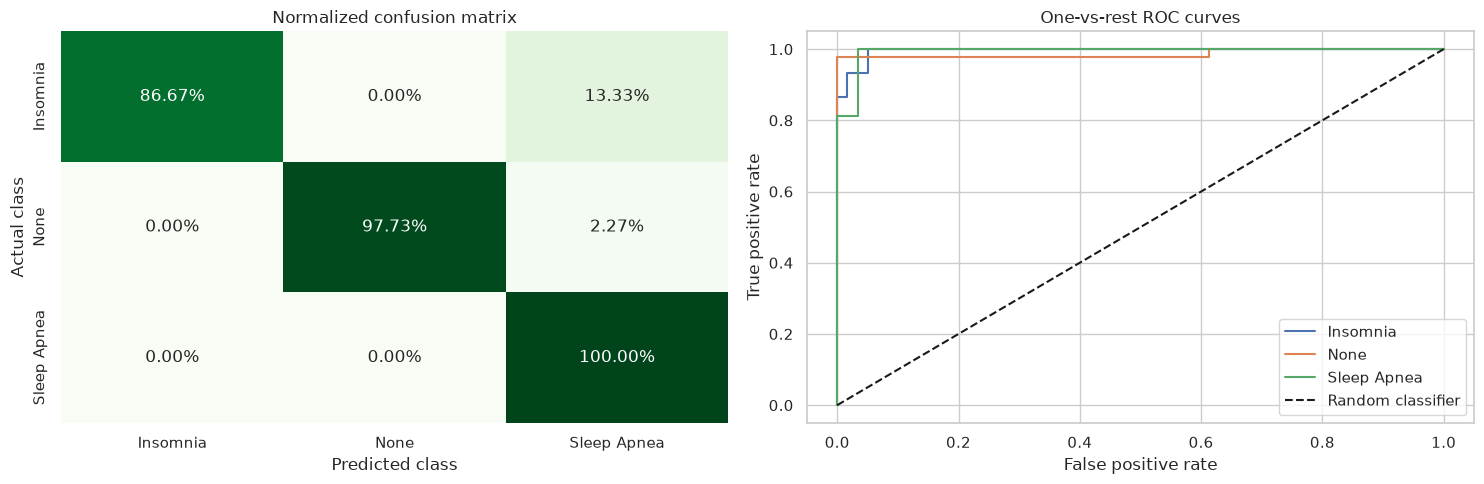

In [15]:
cm_normalized = confusion_matrix(y_test, y_pred, labels=classes, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Greens", cbar=False, xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Normalized confusion matrix")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")

for index, class_name in enumerate(classes):
    binary_actual = (y_test == class_name).astype(int)
    fpr, tpr, _ = roc_curve(binary_actual, y_scores[:, index])
    axes[1].plot(fpr, tpr, label=class_name)
axes[1].plot([0, 1], [0, 1], "k--", label="Random classifier")
axes[1].set_title("One-vs-rest ROC curves")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend()
plt.tight_layout()
plt.show()

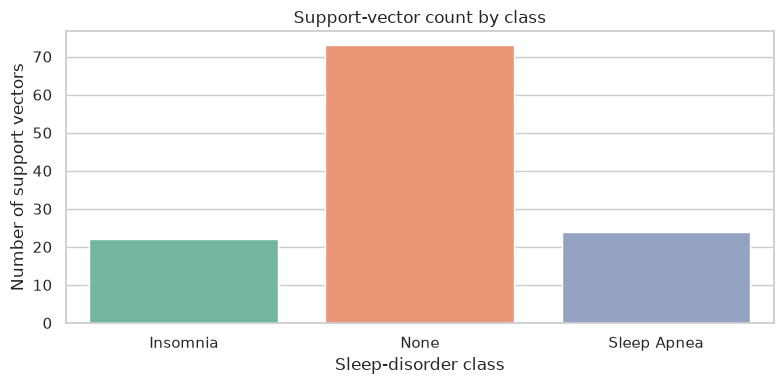

In [16]:
plt.figure(figsize=(8, 4))
sns.barplot(x=classes, y=support_counts, hue=classes, palette="Set2", legend=False)
plt.title("Support-vector count by class")
plt.xlabel("Sleep-disorder class")
plt.ylabel("Number of support vectors")
plt.tight_layout()
plt.show()

**INSIGHT - 15:** A diagonal-heavy confusion matrix means the model usually predicts the correct class. Off-diagonal cells show which disorders are being confused; this is more actionable than a single accuracy value.

**INSIGHT - 16:** ROC curves compare each class against all other classes. A curve closer to the top-left indicates stronger ranking performance, while the diagonal represents random ranking. ROC-AUC should still be interpreted with class balance and per-class recall.

**INSIGHT - 17:** A large support-vector count means many observations lie near the decision boundaries or the classes overlap. This is expected in a small observational health dataset and does not by itself mean the model is bad.

## 8. Compare

Compare the five-fold cross-validation results with the untouched test metrics. A reliable baseline should have reasonably similar validation and test behavior rather than an excellent training score followed by a much weaker test score.

Compare macro and weighted metrics as well. If weighted F1 is much higher than macro F1, the majority `None` class is likely performing better than one or both disorder classes. The per-class report and confusion matrix identify the specific weakness.

The fixed RBF SVM is a baseline, not automatically the final model. A later experiment could compare `C` and `gamma` using nested or training-only cross-validation, but tuning must not use the final test partition.

## 9. Summarize

This notebook loads and documents the sleep-health dataset, maps missing disorder labels to the source convention `None`, parses blood pressure into numeric features, removes the person identifier, and checks class balance and missingness. EDA describes distributions, group patterns, and correlations before modeling.

The modeling pipeline performs training-fitted imputation, one-hot encoding, and standardization before fitting a balanced RBF-kernel SVM. A stratified 80/20 split preserves class proportions, and five-fold cross-validation on the training data provides a stability check. The untouched test data is evaluated with accuracy, balanced accuracy, per-class precision/recall/F1, macro and weighted averages, multiclass ROC-AUC, confusion matrices, ROC curves, and support-vector counts.

## 10. Conclude

**Conclusion.** The RBF SVM is a useful educational model when class boundaries may be nonlinear and the input features are measured on different scales. Its predictions should be explained using the complete metric set, especially per-class recall and macro F1, rather than accuracy alone.

**Limitations.** The dataset is a small public observational sample and may not represent the wider population. Mapping blank disorder labels to `None` is an assumption. The features and labels are not a clinical diagnostic protocol, and the random split does not measure future performance or performance at a different hospital or demographic group. SVM probabilities and ROC-AUC are model-based summaries, not medical certainty.

**Future improvements.** Tune `C` and `gamma` with training-only cross-validation, compare class-weight choices, test repeated or nested validation, evaluate calibration, investigate fairness across demographic groups, and validate on an independent dataset before making any health-related claim.